In [1]:
import requests

# Mapping of file identifiers to URLs
files = {
    "^CNXIT": "https://www.niftyindices.com/IndexConstituent/ind_niftyitlist.csv",
    "^CNXAUTO": "https://www.niftyindices.com/IndexConstituent/ind_niftyautolist.csv",
    "^NSEBANK": "https://www.niftyindices.com/IndexConstituent/ind_niftybanklist.csv",
    "^CNXFMCG": "https://www.niftyindices.com/IndexConstituent/ind_niftyfmcglist.csv",
    "^CNXMEDIA": "https://www.niftyindices.com/IndexConstituent/ind_niftymedialist.csv",
    "^CNXMETAL": "https://www.niftyindices.com/IndexConstituent/ind_niftymetallist.csv",
    "^CNXPSE": "https://www.niftyindices.com/IndexConstituent/ind_niftypselist.csv",
    "^CNXMNC": "https://www.niftyindices.com/IndexConstituent/ind_niftymnclist.csv",
    "^CNXINFRA": "https://www.niftyindices.com/IndexConstituent/ind_niftyinfralist.csv",
    "^CNXREALTY": "https://www.niftyindices.com/IndexConstituent/ind_niftyrealtylist.csv",
    "^CNXENERGY": "https://www.niftyindices.com/IndexConstituent/ind_niftyenergylist.csv",
    "^CNXPSUBANK": "https://www.niftyindices.com/IndexConstituent/ind_niftypsubanklist.csv",
    "^CNXSERVICE": "https://www.niftyindices.com/IndexConstituent/ind_niftyfinancelist.csv",
    "^CNXCONSUM": "https://www.niftyindices.com/IndexConstituent/ind_niftyconsumptionlist.csv",
    "NIFTY_MIDCAP_100.NS": "https://www.niftyindices.com/IndexConstituent/ind_niftymidcap100list.csv"
}

# Common headers to mimic a browser
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                  "AppleWebKit/537.36 (KHTML, like Gecko) "
                  "Chrome/115.0.0.0 Safari/537.36"
}

# Download each file
for name, url in files.items():
    print(f"Downloading {name} from {url}...")
    try:
        with requests.get(url, headers=headers, timeout=15, stream=True) as response:
            response.raise_for_status()  # Raises an HTTPError for bad responses
            filename = f"{name}.csv"
            with open(filename, "wb") as file:
                for chunk in response.iter_content(chunk_size=8192):
                    if chunk:  # Filter out keep-alive chunks
                        file.write(chunk)
        print(f"{filename} downloaded successfully!")
    except requests.exceptions.Timeout:
        print(f"Timeout error: Could not download {name} within the specified time.")
    except requests.exceptions.RequestException as e:
        print(f"Error downloading {name}: {e}")

^CNXIT.csv downloaded successfully!
^CNXAUTO.csv downloaded successfully!
^NSEBANK.csv downloaded successfully!
^CNXFMCG.csv downloaded successfully!
^CNXMEDIA.csv downloaded successfully!
^CNXMETAL.csv downloaded successfully!
^CNXPSE.csv downloaded successfully!
^CNXMNC.csv downloaded successfully!
^CNXINFRA.csv downloaded successfully!
^CNXREALTY.csv downloaded successfully!
^CNXENERGY.csv downloaded successfully!
^CNXPSUBANK.csv downloaded successfully!
^CNXSERVICE.csv downloaded successfully!
^CNXCONSUM.csv downloaded successfully!
NIFTY_MIDCAP_100.NS.csv downloaded successfully!


In [2]:
import pandas as pd

# Dictionary of sector identifiers to CSV file names
# (Matches the naming convention from the previous download code)
sector_files = {
    "^CNXIT": "^CNXIT.csv",
    "^CNXAUTO": "^CNXAUTO.csv",
    "^NSEBANK": "^NSEBANK.csv",
    "^CNXFMCG": "^CNXFMCG.csv",
    "^CNXMEDIA": "^CNXMEDIA.csv",
    "^CNXMETAL": "^CNXMETAL.csv",
    "^CNXPSE": "^CNXPSE.csv",
    "^CNXMNC": "^CNXMNC.csv",
    "^CNXINFRA": "^CNXINFRA.csv",
    "^CNXREALTY": "^CNXREALTY.csv",
    "^CNXENERGY": "^CNXENERGY.csv",
    "^CNXPSUBANK": "^CNXPSUBANK.csv",
    "^CNXSERVICE": "^CNXSERVICE.csv",
    "^CNXCONSUM": "^CNXCONSUM.csv",
    "NIFTY_MIDCAP_100.NS": "NIFTY_MIDCAP_100.NS.csv"
}

# Dictionary to hold symbols for each sector
all_symbols = {}

for sector, filename in sector_files.items():
    try:
        # Read the CSV into a DataFrame
        df = pd.read_csv(filename)
        
        # Extract the 'Symbol' column as a list
        symbols = df['Symbol'].tolist()
        
        # Store the list of symbols in a dictionary
        all_symbols[sector] = symbols
        
        # Print or otherwise use the symbols
        print(f"Symbols for {sector}:")
        print(symbols)
        print("----------")
    except FileNotFoundError:
        print(f"File not found: {filename}. Please ensure it is downloaded.")
    except KeyError:
        print(f"'Symbol' column not found in {filename}. Check the CSV structure.")
    except Exception as e:
        print(f"An error occurred while processing {filename}: {e}")

# Now all_symbols dictionary holds all sector symbols

Symbols for ^CNXIT:
['COFORGE', 'HCLTECH', 'INFY', 'LTM', 'MPHASIS', 'OFSS', 'PERSISTENT', 'TCS', 'TECHM', 'WIPRO']
----------
Symbols for ^CNXAUTO:
['ASHOKLEY', 'BAJAJ-AUTO', 'BHARATFORG', 'BOSCHLTD', 'EICHERMOT', 'EXIDEIND', 'HEROMOTOCO', 'M&M', 'MARUTI', 'MOTHERSON', 'SONACOMS', 'TVSMOTOR', 'TMPV', 'TIINDIA', 'UNOMINDA']
----------
Symbols for ^NSEBANK:
['AUBANK', 'AXISBANK', 'BANKBARODA', 'CANBK', 'FEDERALBNK', 'HDFCBANK', 'ICICIBANK', 'IDFCFIRSTB', 'INDUSINDBK', 'KOTAKBANK', 'PNB', 'SBIN', 'UNIONBANK', 'YESBANK']
----------
Symbols for ^CNXFMCG:
['BRITANNIA', 'COLPAL', 'DABUR', 'EMAMILTD', 'GODREJCP', 'HINDUNILVR', 'ITC', 'MARICO', 'NESTLEIND', 'PATANJALI', 'RADICO', 'TATACONSUM', 'UBL', 'UNITDSPR', 'VBL']
----------
Symbols for ^CNXMEDIA:
['DBCORP', 'HATHWAY', 'NAZARA', 'NETWORK18', 'PVRINOX', 'PFOCUS', 'SAREGAMA', 'SUNTV', 'TIPSMUSIC', 'ZEEL']
----------
Symbols for ^CNXMETAL:
['APLAPOLLO', 'ADANIENT', 'HINDALCO', 'HINDCOPPER', 'HINDZINC', 'JSWSTEEL', 'JSL', 'JINDALSTEL', 'LLOYD

In [3]:
import pandas as pd
import yfinance as yf
import time
from datetime import datetime
from pytz import UTC

# Configuration
MIN_YEARS_HISTORY = 10
MIN_DATA_POINTS = 2000
REQUEST_INTERVAL = 1
MAX_RETRIES = 3

# Sector files mapping
def load_sector_symbols(sector_files):
    all_symbols = {}
    for sector, filename in sector_files.items():
        try:
            df = pd.read_csv(filename)
            symbols = df['Symbol'].tolist()
            symbols_ns = [s if s.endswith('.NS') else f"{s}.NS" for s in symbols]
            all_symbols[sector] = symbols_ns
            print(f"Loaded {len(symbols_ns)} symbols for {sector}")
        except Exception as e:
            print(f"Error loading {filename}: {e}")
            all_symbols[sector] = []
    return all_symbols

# Retry logic for yfinance
def get_historical_data(symbol, retries=MAX_RETRIES):
    for attempt in range(retries):
        try:
            hist = yf.Ticker(symbol).history(period="max", interval="1d", actions=False, timeout=10)
            return hist
        except Exception:
            time.sleep(2)
    return None

# Validate stock history
def check_listing_and_history(hist):
    # Ensure tz-aware index
    if hist.index.tz is None:
        hist.index = hist.index.tz_localize(UTC)
    valid_idx = hist['Close'].dropna().index
    if valid_idx.empty:
        return None, None
    listing_date = valid_idx[0].date()
    # Cutoff for min years
    cutoff = pd.Timestamp.now(tz=UTC) - pd.DateOffset(years=MIN_YEARS_HISTORY)
    has_min_years = valid_idx[0] <= cutoff
    # Count data points since listing
    data_pts = hist.loc[valid_idx[0]:].shape[0]
    return listing_date, has_min_years and data_pts >= MIN_DATA_POINTS

# Main validation
def validate_all(all_symbols):
    valid_list = []
    invalid_list = []
    for sector, syms in all_symbols.items():
        for sym in syms:
            time.sleep(REQUEST_INTERVAL)
            hist = get_historical_data(sym)
            if hist is None or hist.empty:
                continue
            listing_date, is_valid = check_listing_and_history(hist)
            if listing_date is None:
                continue
            entry = {'Sector': sector, 'Symbol': sym, 'ListingDate': listing_date.isoformat()}
            if is_valid:
                valid_list.append(entry)
            else:
                # keep those without 10 yrs
                invalid_list.append(entry)
    return valid_list, invalid_list

# Save to CSV
def save_results(valid_list, invalid_list):
    pd.DataFrame(valid_list).to_csv('validated_stocks2.csv', index=False)
    print("Saved validated_stocks2.csv with stocks >= 10 years history.")
    pd.DataFrame(invalid_list).to_csv('invalidated_stocks.csv', index=False)
    print("Saved invalidated_stocks.csv with listing dates for newer stocks.")

if __name__ == '__main__':
    sector_files = {
        '^CNXIT': '^CNXIT.csv',
        '^CNXAUTO': '^CNXAUTO.csv',
        '^NSEBANK': '^NSEBANK.csv',
        '^CNXFMCG': '^CNXFMCG.csv',
        '^CNXMEDIA': '^CNXMEDIA.csv',
        '^CNXMETAL': '^CNXMETAL.csv',
        '^CNXPSE': '^CNXPSE.csv',
        '^CNXMNC': '^CNXMNC.csv',
        '^CNXINFRA': '^CNXINFRA.csv',
        '^CNXREALTY': '^CNXREALTY.csv',
        '^CNXENERGY': '^CNXENERGY.csv',
        '^CNXPSUBANK': '^CNXPSUBANK.csv',
        '^CNXSERVICE': '^CNXSERVICE.csv',
        '^CNXCONSUM': '^CNXCONSUM.csv',
        'NIFTY_MIDCAP_100.NS': 'NIFTY_MIDCAP_100.NS.csv'
    }
    symbols = load_sector_symbols(sector_files)
    valid, invalid = validate_all(symbols)
    save_results(valid, invalid)

Loaded 10 symbols for ^CNXIT
Loaded 15 symbols for ^CNXAUTO
Loaded 14 symbols for ^NSEBANK
Loaded 15 symbols for ^CNXFMCG
Loaded 10 symbols for ^CNXMEDIA
Loaded 15 symbols for ^CNXMETAL
Loaded 20 symbols for ^CNXPSE
Loaded 30 symbols for ^CNXMNC
Loaded 30 symbols for ^CNXINFRA
Loaded 10 symbols for ^CNXREALTY
Loaded 40 symbols for ^CNXENERGY
Loaded 12 symbols for ^CNXPSUBANK
Loaded 20 symbols for ^CNXSERVICE
Loaded 30 symbols for ^CNXCONSUM
Loaded 100 symbols for NIFTY_MIDCAP_100.NS
Saved validated_stocks2.csv with stocks >= 10 years history.
Saved invalidated_stocks.csv with listing dates for newer stocks.


Enter the number of years for simulation (1-15):  15



Correlation Matrix of Sector Returns (Last 15 Years):
                       ^CNXIT  ^CNXAUTO  ^NSEBANK  ^CNXFMCG  ^CNXMEDIA  \
^CNXIT               1.000000  0.370049  0.332235  0.324507   0.300109   
^CNXAUTO             0.370049  1.000000  0.675429  0.498902   0.547165   
^NSEBANK             0.332235  0.675429  1.000000  0.461531   0.491773   
^CNXFMCG             0.324507  0.498902  0.461531  1.000000   0.362016   
^CNXMEDIA            0.300109  0.547165  0.491773  0.362016   1.000000   
^CNXMETAL            0.334527  0.637536  0.607637  0.387190   0.523676   
^CNXPSE              0.292257  0.618413  0.623142  0.411400   0.532348   
^CNXMNC              0.420985  0.768045  0.658790  0.687435   0.555957   
^CNXINFRA            0.380183  0.717520  0.752840  0.495614   0.557511   
^CNXREALTY           0.299377  0.611257  0.650086  0.409183   0.538363   
^CNXENERGY           0.334014  0.611877  0.626095  0.437827   0.498969   
^CNXPSUBANK          0.213520  0.545747  0.741325  0.3306

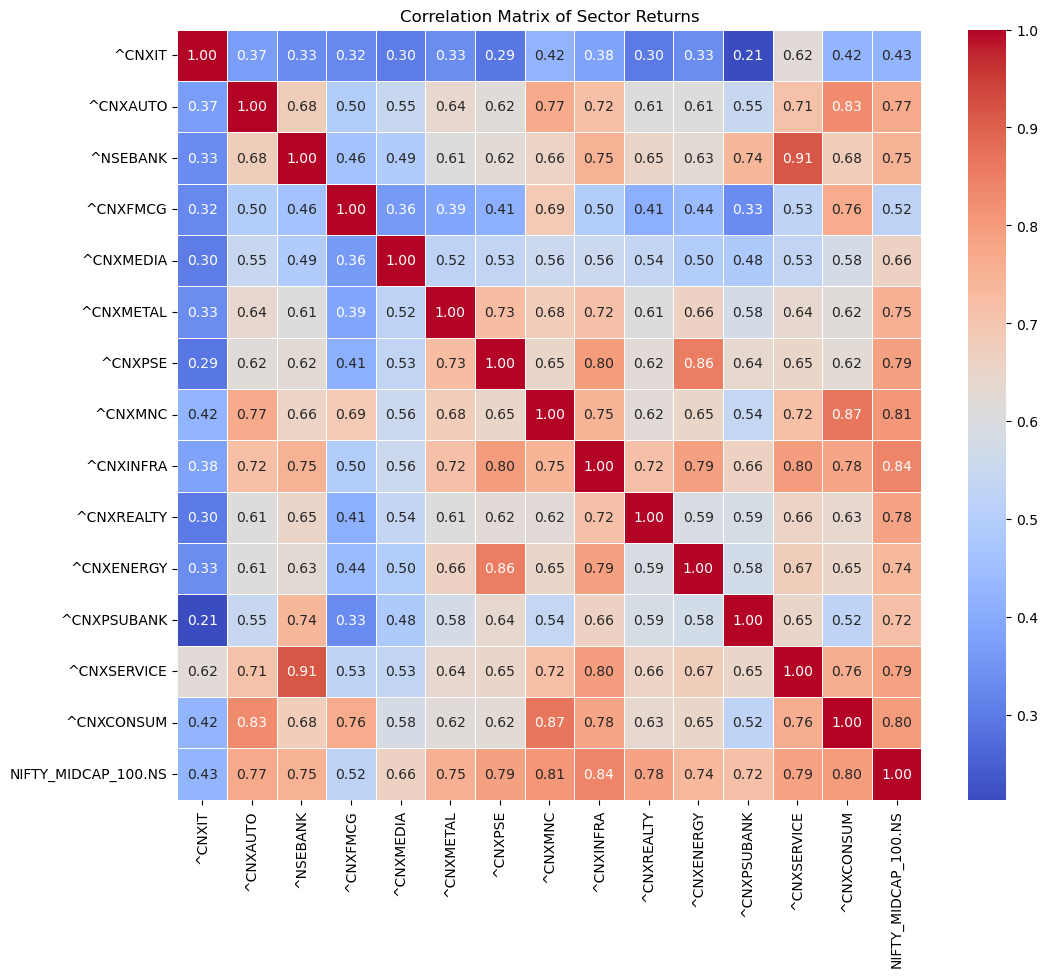

C:\Users\sarda\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:238: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  quarter_end_dates = pd.date_range(start=prices.index[0], end=prices.index[-1], freq='Q')
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size



Sector Cluster Mapping (for Diversification):
  ^CNXIT: Cluster 2
  ^CNXAUTO: Cluster 1
  ^NSEBANK: Cluster 0
  ^CNXFMCG: Cluster 1
  ^CNXMEDIA: Cluster 0
  ^CNXMETAL: Cluster 0
  ^CNXPSE: Cluster 0
  ^CNXMNC: Cluster 1
  ^CNXINFRA: Cluster 1
  ^CNXREALTY: Cluster 0
  ^CNXENERGY: Cluster 0
  ^CNXPSUBANK: Cluster 0
  ^CNXSERVICE: Cluster 1
  ^CNXCONSUM: Cluster 1
  NIFTY_MIDCAP_100.NS: Cluster 1
Valid symbols for NIFTY_MIDCAP_100.NS: ['ACC.NS', 'APLAPOLLO.NS', 'ALKEM.NS', 'ASHOKLEY.NS', 'ASTRAL.NS', 'AUROPHARMA.NS', 'BANKINDIA.NS', 'BHARATFORG.NS', 'BHEL.NS', 'BIOCON.NS', 'BLUESTARCO.NS', 'COFORGE.NS', 'COLPAL.NS', 'CONCOR.NS', 'COROMANDEL.NS', 'CUMMINSIND.NS', 'DABUR.NS', 'EXIDEIND.NS', 'FEDERALBNK.NS', 'FORTIS.NS', 'GMRAIRPORT.NS', 'GLENMARK.NS', 'GODFRYPHLP.NS', 'GODREJPROP.NS', 'HEROMOTOCO.NS', 'HINDPETRO.NS', 'IDFCFIRSTB.NS', 'IRB.NS', 'INDIANB.NS', 'IGL.NS', 'INDUSTOWER.NS', 'INDUSINDBK.NS', 'JUBLFOOD.NS', 'KEI.NS', 'LTF.NS', 'LICHSGFIN.NS', 'LUPIN.NS', 'MRF.NS', 'M&MFIN.NS', 'MA

C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_

Quarter 2011-10-01 to 2011-12-31:
  Selected Sectors: ['^CNXAUTO', '^CNXIT', '^CNXREALTY']
  Sector HRP Weights:
    ^CNXAUTO: 37.50%
      Top Stocks & Weights:
        ('EICHERMOT.NS', 'EICHERMOT.NS'): 28.04%
        ('M&M.NS', 'M&M.NS'): 9.35%
        ('TVSMOTOR.NS', 'TVSMOTOR.NS'): 8.41%
        ('HEROMOTOCO.NS', 'HEROMOTOCO.NS'): 9.35%
        ('BAJAJ-AUTO.NS', 'BAJAJ-AUTO.NS'): 44.86%
    ^CNXIT: 12.50%
      Top Stocks & Weights:
        ('TCS.NS', 'TCS.NS'): 9.35%
        ('INFY.NS', 'INFY.NS'): 9.35%
        ('COFORGE.NS', 'COFORGE.NS'): 8.41%
        ('HCLTECH.NS', 'HCLTECH.NS'): 28.04%
        ('OFSS.NS', 'OFSS.NS'): 44.86%
    ^CNXREALTY: 50.00%
      Top Stocks & Weights:
        ('DLF.NS', 'DLF.NS'): 8.41%
        ('OBEROIRLTY.NS', 'OBEROIRLTY.NS'): 28.04%
        ('BRIGADE.NS', 'BRIGADE.NS'): 44.86%
        ('PHOENIXLTD.NS', 'PHOENIXLTD.NS'): 9.35%
        ('GODREJPROP.NS', 'GODREJPROP.NS'): 9.35%
  Raw Portfolio Return: -12.19%
  STOPLOSS Triggered: Capped Return = -5.0

C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_

Quarter 2012-01-01 to 2012-03-31:
  Selected Sectors: ['^CNXFMCG', '^CNXIT', '^CNXENERGY']
  Sector HRP Weights:
    ^CNXFMCG: 12.50%
      Top Stocks & Weights:
        ('HINDUNILVR.NS', 'HINDUNILVR.NS'): 9.35%
        ('COLPAL.NS', 'COLPAL.NS'): 28.04%
        ('ITC.NS', 'ITC.NS'): 9.35%
        ('PATANJALI.NS', 'PATANJALI.NS'): 8.41%
        ('DABUR.NS', 'DABUR.NS'): 44.86%
    ^CNXIT: 37.50%
      Top Stocks & Weights:
        ('WIPRO.NS', 'WIPRO.NS'): 28.04%
        ('TCS.NS', 'TCS.NS'): 9.35%
        ('INFY.NS', 'INFY.NS'): 9.35%
        ('PERSISTENT.NS', 'PERSISTENT.NS'): 8.41%
        ('COFORGE.NS', 'COFORGE.NS'): 44.86%
    ^CNXENERGY: 50.00%
      Top Stocks & Weights:
        ('POWERGRID.NS', 'POWERGRID.NS'): 8.41%
        ('ONGC.NS', 'ONGC.NS'): 9.35%
        ('PETRONET.NS', 'PETRONET.NS'): 28.04%
        ('NTPC.NS', 'NTPC.NS'): 44.86%
        ('IGL.NS', 'IGL.NS'): 9.35%
  Raw Portfolio Return: 13.45%
  Benchmark Return: 11.13%
  Risk Factor: 0.95
  Effective Portfolio Retu

... (908 outputs left out)

C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_

Quarter 2025-07-01 to 2025-09-30:
  Selected Sectors: ['^CNXCONSUM', '^CNXIT', '^NSEBANK', '^CNXMNC', 'NIFTY_MIDCAP_100.NS', '^CNXFMCG', '^CNXSERVICE', '^CNXAUTO', '^CNXENERGY', '^CNXINFRA']
  Sector HRP Weights:
    ^CNXCONSUM: 3.66%
      Top Stocks & Weights:
        ('TRENT.NS', 'TRENT.NS'): 9.35%
        ('TITAN.NS', 'TITAN.NS'): 8.41%
        ('TVSMOTOR.NS', 'TVSMOTOR.NS'): 9.35%
        ('TATACONSUM.NS', 'TATACONSUM.NS'): 44.86%
        ('ADANIPOWER.NS', 'ADANIPOWER.NS'): 28.04%
    ^CNXIT: 20.58%
      Top Stocks & Weights:
        ('PERSISTENT.NS', 'PERSISTENT.NS'): 8.41%
        ('COFORGE.NS', 'COFORGE.NS'): 44.86%
        ('HCLTECH.NS', 'HCLTECH.NS'): 9.35%
        ('TECHM.NS', 'TECHM.NS'): 28.04%
        ('TCS.NS', 'TCS.NS'): 9.35%
    ^NSEBANK: 6.86%
      Top Stocks & Weights:
        ('ICICIBANK.NS', 'ICICIBANK.NS'): 8.41%
        ('HDFCBANK.NS', 'HDFCBANK.NS'): 28.04%
        ('KOTAKBANK.NS', 'KOTAKBANK.NS'): 9.35%
        ('FEDERALBNK.NS', 'FEDERALBNK.NS'): 9.35%
     

C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_

Quarter 2025-10-01 to 2025-12-31:
  Selected Sectors: ['^CNXCONSUM', '^CNXIT', '^NSEBANK', '^CNXMNC', 'NIFTY_MIDCAP_100.NS', '^CNXFMCG', '^CNXAUTO', '^CNXSERVICE', '^CNXENERGY', '^CNXINFRA']
  Sector HRP Weights:
    ^CNXCONSUM: 3.66%
      Top Stocks & Weights:
        ('TRENT.NS', 'TRENT.NS'): 9.35%
        ('TVSMOTOR.NS', 'TVSMOTOR.NS'): 9.35%
        ('TITAN.NS', 'TITAN.NS'): 8.41%
        ('TATACONSUM.NS', 'TATACONSUM.NS'): 44.86%
        ('ADANIPOWER.NS', 'ADANIPOWER.NS'): 28.04%
    ^CNXIT: 20.58%
      Top Stocks & Weights:
        ('PERSISTENT.NS', 'PERSISTENT.NS'): 8.41%
        ('COFORGE.NS', 'COFORGE.NS'): 44.86%
        ('HCLTECH.NS', 'HCLTECH.NS'): 9.35%
        ('TECHM.NS', 'TECHM.NS'): 28.04%
        ('TCS.NS', 'TCS.NS'): 9.35%
    ^NSEBANK: 6.86%
      Top Stocks & Weights:
        ('ICICIBANK.NS', 'ICICIBANK.NS'): 8.41%
        ('HDFCBANK.NS', 'HDFCBANK.NS'): 28.04%
        ('SBIN.NS', 'SBIN.NS'): 44.86%
        ('KOTAKBANK.NS', 'KOTAKBANK.NS'): 9.35%
        ('FEDERA

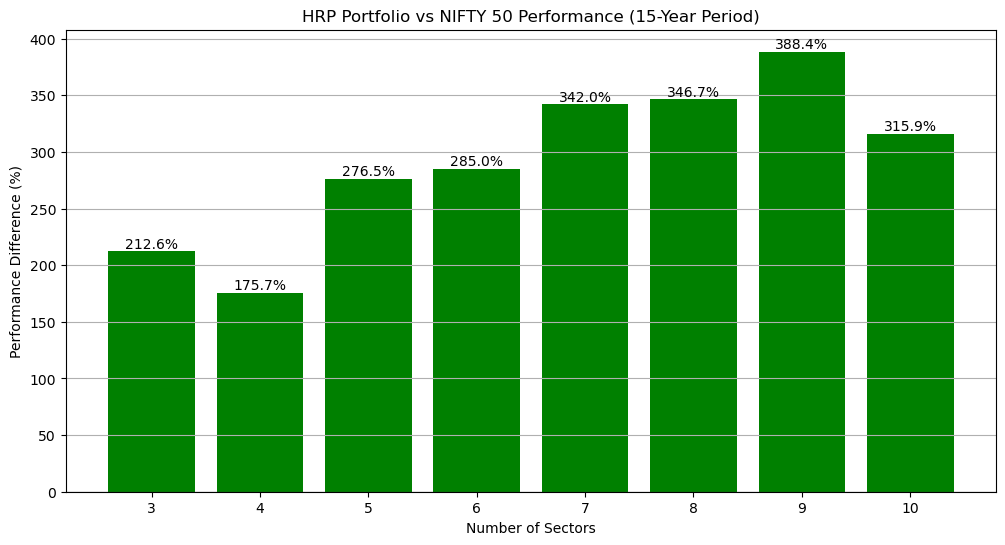


--- Investment Advice as of 2026-03-13 ---
Using training data from 2025-07-03 to 2026-03-12:

--- Top 3 Sectors Recommendation ---
Selected Sectors and Their Top 5 Stocks with Recommended Weights:


C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:504: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  print(f"    {stock}: {float(stock_hrp_weights[stock]):.2%}")



Sector: ^CNXPSUBANK
  Top Stocks: ['SBIN.NS', 'INDIANB.NS', 'BANKINDIA.NS', 'CANBK.NS', 'BANKBARODA.NS']
  Recommended HRP Weights:
    SBIN.NS: 28.04%
    INDIANB.NS: 9.35%
    BANKINDIA.NS: 8.41%
    CANBK.NS: 9.35%
    BANKBARODA.NS: 44.86%


C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:218: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns_stock = prices_stock.pct_change().dropna()
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:504: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  print(f"    {stock}: {float(stock_hrp_weights[stock]):.2%}")



Sector: ^CNXMNC
  Top Stocks: ['VEDL.NS', 'CUMMINSIND.NS', 'ASHOKLEY.NS', '3MINDIA.NS', 'MARUTI.NS']
  Recommended HRP Weights:
    VEDL.NS: 8.41%
    CUMMINSIND.NS: 9.35%
    ASHOKLEY.NS: 28.04%
    3MINDIA.NS: 44.86%
    MARUTI.NS: 9.35%


C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:504: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  print(f"    {stock}: {float(stock_hrp_weights[stock]):.2%}")


... (94 outputs left out)


Sector: ^NSEBANK
  Top Stocks: ['SBIN.NS', 'FEDERALBNK.NS', 'CANBK.NS', 'BANKBARODA.NS', 'UNIONBANK.NS']
  Recommended HRP Weights:
    SBIN.NS: 9.35%
    FEDERALBNK.NS: 28.04%
    CANBK.NS: 8.41%
    BANKBARODA.NS: 44.86%
    UNIONBANK.NS: 9.35%


C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:218: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns_stock = prices_stock.pct_change().dropna()
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:504: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  print(f"    {stock}: {float(stock_hrp_weights[stock]):.2%}")



Sector: ^CNXINFRA
  Top Stocks: ['CUMMINSIND.NS', 'ASHOKLEY.NS', 'BHARATFORG.NS', 'NTPC.NS', 'ONGC.NS']
  Recommended HRP Weights:
    CUMMINSIND.NS: 9.35%
    ASHOKLEY.NS: 28.04%
    BHARATFORG.NS: 9.35%
    NTPC.NS: 8.41%
    ONGC.NS: 44.86%

Sector: NIFTY_MIDCAP_100.NS
  Top Stocks: ['NATIONALUM.NS', 'CUMMINSIND.NS', 'ASHOKLEY.NS', 'INDIANB.NS', 'BHARATFORG.NS']
  Recommended HRP Weights:
    NATIONALUM.NS: 28.04%
    CUMMINSIND.NS: 8.41%
    ASHOKLEY.NS: 9.35%
    INDIANB.NS: 44.86%
    BHARATFORG.NS: 9.35%
------------------------------------------------------------


C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:218: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns_stock = prices_stock.pct_change().dropna()
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  weights[left] *= cluster_sizes[right] / total_size
C:\Users\sarda\AppData\Local\Temp\ipykernel_44080\124261850.py:504: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  print(f"    {stock}: {float(stock_hrp_weights[stock]):.2%}")


In [4]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from sklearn.cluster import KMeans
import scipy.cluster.hierarchy as sch
import scipy.spatial.distance as ssd
import requests
import time

# =============================================================================
# 0. User Input: Number of Years for Simulation (between 1 and 15)
# =============================================================================
while True:
    try:
        num_years = int(input("Enter the number of years for simulation (1-15): "))
        if 1 <= num_years <= 15:
            break
        else:
            print("Please enter a number between 1 and 15.")
    except ValueError:
        print("Invalid input. Please enter an integer between 1 and 15.")

# =============================================================================
# 1. Sector Data Download and Preprocessing (using sector indices)
# =============================================================================
sector_tickers = [
    "^CNXIT", "^CNXAUTO", "^NSEBANK", "^CNXFMCG", "^CNXMEDIA",
    "^CNXMETAL", "^CNXPSE", "^CNXMNC", "^CNXINFRA",
    "^CNXREALTY", "^CNXENERGY", "^CNXPSUBANK", "^CNXSERVICE",
    "^CNXCONSUM", "NIFTY_MIDCAP_100.NS"
]

end_date = datetime.today()
start_date = end_date - timedelta(days=365 * num_years)

data_dict = {}
for ticker in sector_tickers:
    df = yf.download(ticker, start=start_date, end=end_date, progress=False, auto_adjust=True)
    if not df.empty and 'Close' in df.columns:
        data_dict[ticker] = df['Close']
    else:
        print(f"Data for {ticker} is missing or incomplete.")

if not data_dict:
    raise ValueError("No sector data downloaded. Check ticker symbols or network connection.")

prices = pd.concat(data_dict, axis=1).dropna()
# If columns are multi-index, reset to plain tickers.
if isinstance(prices.columns, pd.MultiIndex):
    prices.columns = prices.columns.get_level_values(0)
returns = prices.pct_change().dropna()

# =============================================================================
# 2. Download Benchmark Data for Trend/Stoploss Analysis (NIFTY 50)
# =============================================================================
benchmark_ticker = "^NSEI"
benchmark_data = yf.download(benchmark_ticker, start=start_date, end=end_date, progress=False, auto_adjust=True)
if benchmark_data.empty:
    raise ValueError("No benchmark data downloaded for trend analysis.")
benchmark_series = benchmark_data['Close'].squeeze()

# =============================================================================
# 3. Correlation Analysis & Clustering for Diversification (Sector Level)
# =============================================================================
correlation_matrix = returns.corr()
print(f"\nCorrelation Matrix of Sector Returns (Last {num_years} Years):")
print(correlation_matrix)

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Sector Returns")
plt.show()

kmeans = KMeans(n_clusters=3, random_state=42)
sector_features = correlation_matrix.values
sector_labels = kmeans.fit_predict(sector_features)
sector_cluster_map = dict(zip(correlation_matrix.columns, sector_labels))
print("\nSector Cluster Mapping (for Diversification):")
for sector, cluster in sector_cluster_map.items():
    print(f"  {sector}: Cluster {cluster}")

# =============================================================================
# 4. Validated Stocks Extraction: Read Valid Stock Components from CSV File
# =============================================================================
# Expect file 'validated_stocks.csv' with columns "Sector" and "Symbol"
try:
    df_valid = pd.read_csv('validated_stocks2.csv')
    all_symbols = {}
    for sector, group in df_valid.groupby('Sector'):
        symbols = group['Symbol'].tolist()
        # Ensure each symbol ends with ".NS"
        symbols = [s if s.endswith('.NS') else s + '.NS' for s in symbols]
        all_symbols[sector] = symbols
        print(f"Valid symbols for {sector}: {symbols}")
        print("----------")
except Exception as e:
    print("Error reading validated stocks file:", e)
    all_symbols = {}

# =============================================================================
# 4a. Read Listing Dates for Stocks from Invalidated Stocks File
# =============================================================================
# Expect file 'invalidated_stocks.csv' with columns "Sector", "Symbol", and "ListingDate"
# Build dictionary mapping each symbol (with .NS appended if needed) to its listing date.
listing_dates = {}
try:
    df_invalid = pd.read_csv('invalidated_stocks.csv')
    df_invalid['ListingDate'] = pd.to_datetime(df_invalid['ListingDate'])
    for idx, row in df_invalid.iterrows():
        symbol = row['Symbol']
        if not symbol.endswith('.NS'):
            symbol += '.NS'
        listing_dates[symbol] = row['ListingDate']
    print("\nListing dates loaded for stocks from invalidated_stocks.csv.")
except Exception as e:
    print("Error reading invalidated stocks file:", e)
    listing_dates = {}

# =============================================================================
# 5. HRP Weight Calculation Function (with Numerical Stability Fixes)
# =============================================================================
def get_hrp_weights(returns_df):
    """
    Calculate Hierarchical Risk Parity (HRP) weights.
    """
    if returns_df.shape[1] < 2:
        return pd.Series(1.0, index=returns_df.columns)
    
    corr = returns_df.corr().fillna(0)
    corr = 0.5 * (corr + corr.T)
    np.fill_diagonal(corr.values, 1.0)
    dist = np.sqrt(np.clip(0.5 * (1 - corr), 0.0, 1.0))
    dist = 0.5 * (dist + dist.T)
    dist = np.nan_to_num(dist, nan=0.0, posinf=0.0, neginf=0.0)
    
    condensed_dist = ssd.squareform(dist, checks=False)
    link = sch.linkage(condensed_dist, method='ward')
    sorted_indices = sch.leaves_list(link)
    ordered_tickers = returns_df.columns[sorted_indices]
    
    weights = pd.Series(1, index=ordered_tickers)
    cluster_sizes = pd.Series(1, index=ordered_tickers)
    
    for i in range(len(ordered_tickers) - 1):
        left, right = ordered_tickers[i], ordered_tickers[i+1]
        total_size = cluster_sizes[left] + cluster_sizes[right]
        weights[left] *= cluster_sizes[right] / total_size
        weights[right] *= cluster_sizes[left] / total_size
        cluster_sizes[left] = total_size
        cluster_sizes[right] = total_size
    
    return weights / weights.sum()

# =============================================================================
# 6. Diversified Sector Selection Function
# =============================================================================
def select_diversified_sectors(sharpe_scores, n, cluster_map):
    """
    Select top-n sectors based on Sharpe ratio while ensuring diversification.
    """
    sorted_sectors = sharpe_scores.sort_values(ascending=False).index.tolist()
    unique_selected = []
    used_clusters = set()
    for s in sorted_sectors:
        if cluster_map[s] not in used_clusters:
            unique_selected.append(s)
            used_clusters.add(cluster_map[s])
    selected = unique_selected.copy()
    for s in sorted_sectors:
        if len(selected) >= n:
            break
        if s not in selected:
            selected.append(s)
    return selected[:n]

# =============================================================================
# 7. Function to Select Top Stocks within a Sector
# =============================================================================
def get_top_stocks(sector, train_start, train_end, top_n=5):
    """
    For a given sector, download historical data for its valid component stocks (from all_symbols)
    over the training period. If a stock was listed after train_start, adjust the start date accordingly.
    Compute Sharpe ratios and return the top 'top_n' stocks along with their HRP weights.
    """
    symbols = all_symbols.get(sector, [])
    if not symbols:
        print(f"No valid symbols available for sector {sector}.")
        return [], pd.Series(dtype=float)
    
    stock_data = {}
    for symbol in symbols:
        # Adjust training start date based on listing date if available.
        adj_train_start = train_start
        if symbol in listing_dates:
            list_date = listing_dates[symbol]
            if list_date > pd.to_datetime(train_start):
                adj_train_start = list_date.strftime("%Y-%m-%d")
        try:
            df = yf.download(symbol, start=adj_train_start, end=train_end, progress=False, auto_adjust=True)
            if not df.empty and 'Close' in df.columns:
                stock_data[symbol] = df['Close']
        except Exception as e:
            print(f"Error downloading data for {symbol}: {e}")
            continue

    if not stock_data:
        print(f"No training data available for stocks in sector {sector}.")
        return [], pd.Series(dtype=float)
    
    prices_stock = pd.concat(stock_data, axis=1).dropna(how='all', axis=0)
    if prices_stock.empty:
        print(f"No overlapping training data for stocks in sector {sector}.")
        return [], pd.Series(dtype=float)
    
    returns_stock = prices_stock.pct_change().dropna()
    if returns_stock.empty:
        print(f"Insufficient returns data for stocks in sector {sector}.")
        return [], pd.Series(dtype=float)
    
    sharpe = returns_stock.mean() / returns_stock.std()
    sharpe = sharpe.dropna()
    if sharpe.empty:
        print(f"Sharpe ratio calculation failed for sector {sector}.")
        return [], pd.Series(dtype=float)
    
    top_stocks = sharpe.sort_values(ascending=False).head(top_n).index.tolist()
    selected_returns = returns_stock[top_stocks]
    hrp_weights_stocks = get_hrp_weights(selected_returns)
    return top_stocks, hrp_weights_stocks

# =============================================================================
# 8. Quarterly Rebalancing Simulation with Enhanced Risk Management & Transaction Costs
# =============================================================================
print("\n--- Quarterly Rebalancing Simulation with Enhanced Risk Management ---\n")
quarter_end_dates = pd.date_range(start=prices.index[0], end=prices.index[-1], freq='Q')
initial_capital = 100000
stoploss_pct = 0.05  # 5% stoploss threshold
transaction_cost_rate = 0.00075  # 0.15% per trade (0.075% per buy and sell)

results_summary = []
all_quarterly_results = {}

def get_previous_quarter_risk_factor(i, benchmark_series, quarter_end_dates):
    if i == 0:
        return 1.0
    prev_q_start = prices.index[0] if i-1 == 0 else quarter_end_dates[i-2] + pd.Timedelta(days=1)
    prev_q_end = quarter_end_dates[i-1]
    benchmark_prev = benchmark_series[(benchmark_series.index >= prev_q_start) & (benchmark_series.index <= prev_q_end)]
    if benchmark_prev.empty:
        return 1.0
    prev_return = (benchmark_prev.iloc[-1] / benchmark_prev.iloc[0]) - 1
    return np.clip(1 + prev_return, 0.5, 1.0)

# For each simulation run (number of sectors n), also compute annualized alpha and beta.
for n in range(3, 11):
    cumulative_value = initial_capital
    quarterly_results = []  # to store each quarter's results (including returns and quarter_end)
    
    print(f"\n===== Simulating for Top {n} Sectors =====\n")
    
    for i, q_end in enumerate(quarter_end_dates):
        q_start = prices.index[0] if i == 0 else quarter_end_dates[i-1] + pd.Timedelta(days=1)
        if q_start >= prices.index[-1]:
            break
        
        training_end = q_start - pd.Timedelta(days=1)
        training_prices = prices[prices.index <= training_end]
        if training_prices.empty:
            continue
        training_returns = training_prices.pct_change().dropna()
        if training_returns.empty:
            continue
        
        sharpe_scores = training_returns.mean() / training_returns.std()
        selected_sectors = select_diversified_sectors(sharpe_scores, n, sector_cluster_map)
        if len(selected_sectors) == 0:
            continue
        
        selected_training_returns = training_returns[selected_sectors]
        sector_hrp_weights = get_hrp_weights(selected_training_returns)
        
        # For each selected sector, determine top 5 stocks and get their HRP weights.
        sector_stock_info = {}
        sector_stock_returns = {}
        sector_weighted_returns = {}
        
        for sector in selected_sectors:
            train_start_str = training_prices.index[0].strftime("%Y-%m-%d")
            train_end_str = training_end.strftime("%Y-%m-%d")
            top_stocks, stock_hrp_weights = get_top_stocks(sector, train_start_str, q_start.strftime("%Y-%m-%d"), top_n=5)
            if not top_stocks:
                continue
            # Ensure tickers are strings.
            top_stocks = [s if isinstance(s, str) else s[0] for s in top_stocks]
            stock_prices = yf.download(top_stocks,
                                       start=q_start.strftime("%Y-%m-%d"),
                                       end=q_end.strftime("%Y-%m-%d"),
                                       progress=False, auto_adjust=True)
            if 'Close' in stock_prices.columns:
                stock_prices = stock_prices['Close']
            stock_prices = stock_prices.dropna(how='all', axis=0)
            if stock_prices.empty or len(stock_prices) < 2:
                continue
            start_prices = stock_prices.iloc[0]
            end_prices = stock_prices.iloc[-1]
            stock_ret = (end_prices / start_prices) - 1
            weighted_return = np.dot(stock_hrp_weights[top_stocks], stock_ret[top_stocks])
            
            sector_stock_info[sector] = {
                'top_stocks': top_stocks,
                'stock_hrp_weights': stock_hrp_weights[top_stocks].to_dict()
            }
            sector_stock_returns[sector] = stock_ret.to_dict()
            sector_weighted_returns[sector] = weighted_return
        
        if not sector_weighted_returns:
            continue
        
        overall_return = 0
        for sector in selected_sectors:
            if sector in sector_weighted_returns:
                overall_return += sector_hrp_weights[sector] * sector_weighted_returns[sector]
        
        # Compute benchmark return for the quarter.
        benchmark_q = benchmark_series[(benchmark_series.index >= q_start) & (benchmark_series.index <= q_end)]
        if benchmark_q.empty:
            bench_return = np.nan
        else:
            bench_return = (benchmark_q.iloc[-1] / benchmark_q.iloc[0]) - 1
        
        # Modified Stoploss: if daily cumulative drop is below threshold.
        period_prices = prices.loc[(prices.index >= q_start) & (prices.index <= q_end), selected_sectors]
        if period_prices.empty or len(period_prices) < 2:
            continue
        daily_returns = period_prices.pct_change().dropna()
        daily_portfolio_returns = daily_returns.apply(lambda row: np.dot([sector_hrp_weights[s] for s in selected_sectors], row[selected_sectors]), axis=1)
        cum_daily = (1 + daily_portfolio_returns).cumprod()
        if cum_daily.min() < (1 - stoploss_pct):
            stoploss_triggered = True
            stoploss_return = overall_return if overall_return > -stoploss_pct else -stoploss_pct
        else:
            stoploss_triggered = False
            stoploss_return = overall_return
        
        risk_factor = get_previous_quarter_risk_factor(i, benchmark_series, quarter_end_dates)
        effective_return = risk_factor * stoploss_return
        
        net_value_entry = cumulative_value * (1 - transaction_cost_rate)
        new_value = net_value_entry * (1 + effective_return)
        net_value_exit = new_value * (1 - transaction_cost_rate)
        cumulative_value = net_value_exit
        
        # Save quarterly data with quarter_end date.
        quarterly_results.append({
            'quarter_end': q_end,  # we'll use this to group by year
            'effective_return': effective_return,
            'benchmark_return': bench_return
        })
        
        print(f"Quarter {q_start.date()} to {q_end.date()}:")
        print(f"  Selected Sectors: {selected_sectors}")
        print("  Sector HRP Weights:")
        for sector in selected_sectors:
            print(f"    {sector}: {sector_hrp_weights[sector]:.2%}")
            if sector in sector_stock_info:
                info = sector_stock_info[sector]
                print("      Top Stocks & Weights:")
                for stock, wt in info['stock_hrp_weights'].items():
                    print(f"        {stock}: {float(wt):.2%}")
        print(f"  Raw Portfolio Return: {overall_return:.2%}")
        if stoploss_triggered:
            print(f"  STOPLOSS Triggered: Capped Return = {stoploss_return:.2%}")
        print(f"  Benchmark Return: {bench_return:.2%}")
        print(f"  Risk Factor: {risk_factor:.2f}")
        print(f"  Effective Portfolio Return: {effective_return:.2%}")
        print(f"  Cumulative Value after Transaction Costs: ₹{cumulative_value:,.2f}")
        print("-" * 80)
    
    # --- Annual Alpha/Beta Calculation ---
    # Group quarterly results by year and compound returns to get annual returns.
    annual_port_returns = {}
    annual_bench_returns = {}
    for res in quarterly_results:
        year = res['quarter_end'].year
        annual_port_returns.setdefault(year, []).append(1 + res['effective_return'])
        annual_bench_returns.setdefault(year, []).append(1 + res['benchmark_return'] if not np.isnan(res['benchmark_return']) else np.nan)
    
    annual_port = []
    annual_bench = []
    for year in sorted(annual_port_returns.keys()):
        # Only include year if all benchmark returns are numbers.
        if np.isnan(annual_bench_returns[year]).any():
            continue
        annual_r = np.prod(annual_port_returns[year]) - 1
        annual_b = np.prod(annual_bench_returns[year]) - 1
        annual_port.append(annual_r)
        annual_bench.append(annual_b)
    annual_port = np.array(annual_port)
    annual_bench = np.array(annual_bench)
    
    if len(annual_bench) >= 2:
        beta, alpha = np.polyfit(annual_bench, annual_port, 1)
    else:
        beta, alpha = np.nan, np.nan

    results_summary.append({
        'Number of Sectors': n,
        'HRP Portfolio Value': cumulative_value,
        'Annualized Volatility': np.std([res['effective_return'] for res in quarterly_results]) * np.sqrt(4) if len(quarterly_results) > 1 else np.nan,
        'Alpha': alpha,
        'Beta': beta
    })
    all_quarterly_results[n] = quarterly_results

hrp_results_df = pd.DataFrame(results_summary)
print("\n=== Simulation Summary for HRP Portfolios (Top N Sectors) ===")
print(hrp_results_df)

# =============================================================================
# 9. Fixed Benchmark Analysis (NIFTY 50)
# =============================================================================
initial_capital_bench = 100000
benchmark_results = []

filtered_data = benchmark_series[benchmark_series.index >= pd.Timestamp(start_date)]
if len(filtered_data) < 2:
    raise ValueError("Not enough benchmark data for the selected period.")

start_price = float(filtered_data.iloc[0])
end_price = float(filtered_data.iloc[-1])
total_return = (end_price / start_price) - 1
cagr = ((1 + total_return) ** (1/num_years)) - 1
final_value = initial_capital_bench * (1 + total_return)

benchmark_results.append({
    'Time Period': f"{num_years} Years",
    'Total Return (%)': round(total_return * 100, 2),
    'CAGR (%)': round(cagr * 100, 2),
    'Final Portfolio Value': round(final_value, 2)
})

benchmark_results_df = pd.DataFrame(benchmark_results)
print(f"\n=== NIFTY 50 Benchmark Performance ({num_years} Years) ===")
print(benchmark_results_df.to_string(index=False))

nifty_final = final_value
comparison_df = hrp_results_df.copy()
comparison_df['NIFTY Value'] = nifty_final
comparison_df['Outperformance (%)'] = (
    (comparison_df['HRP Portfolio Value'] - nifty_final) / nifty_final * 100
).round(2)

print(f"\n=== Final Performance Comparison ({num_years}-Year Period) ===")
print(comparison_df[['Number of Sectors', 'HRP Portfolio Value', 'NIFTY Value', 'Outperformance (%)', 'Alpha', 'Beta']].to_string(index=False))

plt.figure(figsize=(12, 6))
bars = plt.bar(
    comparison_df['Number of Sectors'],
    comparison_df['Outperformance (%)'],
    color=np.where(comparison_df['Outperformance (%)'] > 0, 'g', 'r')
)
plt.title(f"HRP Portfolio vs NIFTY 50 Performance ({num_years}-Year Period)")
plt.xlabel("Number of Sectors")
plt.ylabel("Performance Difference (%)")
plt.axhline(0, color='black', linewidth=0.8)
plt.grid(axis='y')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:.1f}%', ha='center', va='bottom')
plt.show()

# =============================================================================
# 10. Investment Advice Based on Last 1 Year Data (Stock-Level)
# =============================================================================
advice_date = datetime.today()
advice_training_end = advice_date - timedelta(days=1)
advice_training_start = advice_training_end - timedelta(days=252)
if advice_training_start < prices.index[0]:
    advice_training_start = prices.index[0]

advice_training_prices = prices.loc[advice_training_start:advice_training_end].ffill()
advice_training_returns = advice_training_prices.pct_change().dropna()

print(f"\n--- Investment Advice as of {advice_date.date()} ---")
print(f"Using training data from {advice_training_start.date()} to {advice_training_end.date()}:\n")
for n in range(3, 11):
    sharpe_scores = advice_training_returns.mean() / advice_training_returns.std()
    top_n_sectors = select_diversified_sectors(sharpe_scores, n, sector_cluster_map)
    if not top_n_sectors:
        continue
    print(f"--- Top {n} Sectors Recommendation ---")
    print("Selected Sectors and Their Top 5 Stocks with Recommended Weights:")
    for sector in top_n_sectors:
        top_stocks, stock_hrp_weights = get_top_stocks(sector, advice_training_prices.index[0].strftime("%Y-%m-%d"), advice_training_end.strftime("%Y-%m-%d"), top_n=5)
        if top_stocks:
            top_stocks = [s if isinstance(s, str) else s[0] for s in top_stocks]
            print(f"\nSector: {sector}")
            print(f"  Top Stocks: {top_stocks}")
            print("  Recommended HRP Weights:")
            for stock in top_stocks:
                print(f"    {stock}: {float(stock_hrp_weights[stock]):.2%}")
    print("-" * 60)

In [14]:
import requests

# Mapping of file identifiers to URLs
files = {
    "^CNXIT": "https://www.niftyindices.com/IndexConstituent/ind_niftyitlist.csv",
    "^CNXAUTO": "https://www.niftyindices.com/IndexConstituent/ind_niftyautolist.csv",
    "^NSEBANK": "https://www.niftyindices.com/IndexConstituent/ind_niftybanklist.csv",
    "^CNXFMCG": "https://www.niftyindices.com/IndexConstituent/ind_niftyfmcglist.csv",
    "^CNXMEDIA": "https://www.niftyindices.com/IndexConstituent/ind_niftymedialist.csv",
    "^CNXMETAL": "https://www.niftyindices.com/IndexConstituent/ind_niftymetallist.csv",
    "^CNXPSE": "https://www.niftyindices.com/IndexConstituent/ind_niftypselist.csv",
    "^CNXMNC": "https://www.niftyindices.com/IndexConstituent/ind_niftymnclist.csv",
    "^CNXINFRA": "https://www.niftyindices.com/IndexConstituent/ind_niftyinfralist.csv",
    "^CNXREALTY": "https://www.niftyindices.com/IndexConstituent/ind_niftyrealtylist.csv",
    "^CNXENERGY": "https://www.niftyindices.com/IndexConstituent/ind_niftyenergylist.csv",
    "^CNXPSUBANK": "https://www.niftyindices.com/IndexConstituent/ind_niftypsubanklist.csv",
    "^CNXSERVICE": "https://www.niftyindices.com/IndexConstituent/ind_niftyfinancelist.csv",
    "^CNXCONSUM": "https://www.niftyindices.com/IndexConstituent/ind_niftyconsumptionlist.csv",
    "NIFTY_MIDCAP_100.NS": "https://www.niftyindices.com/IndexConstituent/ind_niftymidcap100list.csv"
}

# Common headers to mimic a browser
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                  "AppleWebKit/537.36 (KHTML, like Gecko) "
                  "Chrome/115.0.0.0 Safari/537.36"
}

# Download each file
for name, url in files.items():
    print(f"Downloading {name} from {url}...")
    try:
        with requests.get(url, headers=headers, timeout=15, stream=True) as response:
            response.raise_for_status()  # Raises an HTTPError for bad responses
            filename = f"{name}.csv"
            with open(filename, "wb") as file:
                for chunk in response.iter_content(chunk_size=8192):
                    if chunk:  # Filter out keep-alive chunks
                        file.write(chunk)
        print(f"{filename} downloaded successfully!")
    except requests.exceptions.Timeout:
        print(f"Timeout error: Could not download {name} within the specified time.")
    except requests.exceptions.RequestException as e:
        print(f"Error downloading {name}: {e}")

^CNXIT.csv downloaded successfully!
^CNXAUTO.csv downloaded successfully!
^NSEBANK.csv downloaded successfully!
^CNXFMCG.csv downloaded successfully!
^CNXMEDIA.csv downloaded successfully!
^CNXMETAL.csv downloaded successfully!
^CNXPSE.csv downloaded successfully!
^CNXMNC.csv downloaded successfully!
^CNXINFRA.csv downloaded successfully!
^CNXREALTY.csv downloaded successfully!
^CNXENERGY.csv downloaded successfully!
^CNXPSUBANK.csv downloaded successfully!
^CNXSERVICE.csv downloaded successfully!
^CNXCONSUM.csv downloaded successfully!
NIFTY_MIDCAP_100.NS.csv downloaded successfully!


In [16]:
import pandas as pd

# Dictionary of sector identifiers to CSV file names
# (Matches the naming convention from the previous download code)
sector_files = {
    "^CNXIT": "^CNXIT.csv",
    "^CNXAUTO": "^CNXAUTO.csv",
    "^NSEBANK": "^NSEBANK.csv",
    "^CNXFMCG": "^CNXFMCG.csv",
    "^CNXMEDIA": "^CNXMEDIA.csv",
    "^CNXMETAL": "^CNXMETAL.csv",
    "^CNXPSE": "^CNXPSE.csv",
    "^CNXMNC": "^CNXMNC.csv",
    "^CNXINFRA": "^CNXINFRA.csv",
    "^CNXREALTY": "^CNXREALTY.csv",
    "^CNXENERGY": "^CNXENERGY.csv",
    "^CNXPSUBANK": "^CNXPSUBANK.csv",
    "^CNXSERVICE": "^CNXSERVICE.csv",
    "^CNXCONSUM": "^CNXCONSUM.csv",
    "NIFTY_MIDCAP_100.NS": "NIFTY_MIDCAP_100.NS.csv"
}

# Dictionary to hold symbols for each sector
all_symbols = {}

for sector, filename in sector_files.items():
    try:
        # Read the CSV into a DataFrame
        df = pd.read_csv(filename)
        
        # Extract the 'Symbol' column as a list
        symbols = df['Symbol'].tolist()
        
        # Store the list of symbols in a dictionary
        all_symbols[sector] = symbols
        
        # Print or otherwise use the symbols
        print(f"Symbols for {sector}:")
        print(symbols)
        print("----------")
    except FileNotFoundError:
        print(f"File not found: {filename}. Please ensure it is downloaded.")
    except KeyError:
        print(f"'Symbol' column not found in {filename}. Check the CSV structure.")
    except Exception as e:
        print(f"An error occurred while processing {filename}: {e}")

# Now all_symbols dictionary holds all sector symbols

Symbols for ^CNXIT:
['COFORGE', 'HCLTECH', 'INFY', 'LTIM', 'MPHASIS', 'OFSS', 'PERSISTENT', 'TCS', 'TECHM', 'WIPRO']
----------
Symbols for ^CNXAUTO:
['ASHOKLEY', 'BAJAJ-AUTO', 'BALKRISIND', 'BHARATFORG', 'BOSCHLTD', 'EICHERMOT', 'EXIDEIND', 'HEROMOTOCO', 'MRF', 'M&M', 'MARUTI', 'MOTHERSON', 'TVSMOTOR', 'TATAMOTORS', 'TIINDIA']
----------
Symbols for ^NSEBANK:
['AUBANK', 'AXISBANK', 'BANKBARODA', 'CANBK', 'FEDERALBNK', 'HDFCBANK', 'ICICIBANK', 'IDFCFIRSTB', 'INDUSINDBK', 'KOTAKBANK', 'PNB', 'SBIN']
----------
Symbols for ^CNXFMCG:
['BRITANNIA', 'COLPAL', 'DABUR', 'EMAMILTD', 'GODREJCP', 'HINDUNILVR', 'ITC', 'MARICO', 'NESTLEIND', 'PATANJALI', 'RADICO', 'TATACONSUM', 'UBL', 'UNITDSPR', 'VBL']
----------
Symbols for ^CNXMEDIA:
['DBCORP', 'DISHTV', 'HATHWAY', 'NAZARA', 'NETWORK18', 'PVRINOX', 'SAREGAMA', 'SUNTV', 'TIPSMUSIC', 'ZEEL']
----------
Symbols for ^CNXMETAL:
['APLAPOLLO', 'ADANIENT', 'HINDALCO', 'HINDCOPPER', 'HINDZINC', 'JSWSTEEL', 'JSL', 'JINDALSTEL', 'LLOYDSME', 'NMDC', 'NATIO

In [25]:
import pandas as pd
import yfinance as yf
from datetime import datetime, timedelta
from pytz import UTC
import time

# Configuration
MIN_YEARS_HISTORY = 10
MIN_DATA_POINTS_VALID = 2000  # for originally valid stocks
MIN_DATA_POINTS_GRAD = 1000   # for graduates
MIN_YEARS_GRADUATION = 1   # 1 year for invalid to graduate
REQUEST_INTERVAL = 1
MAX_RETRIES = 3

# Load validated and invalidated stocks
validated_file = 'validated_stocks2.csv'
invalidated_file = 'invalidated_stocks.csv'

validated_file = 'validated_stocks2.csv'
invalidated_file = 'invalidated_stocks.csv'

df_valid = pd.read_csv(validated_file)
df_invalid = pd.read_csv(invalidated_file)

def get_historical_data(symbol, retries=MAX_RETRIES):
    for attempt in range(retries):
        try:
            ticker = yf.Ticker(symbol)
            hist = ticker.history(period='max', interval='1d', actions=False, timeout=10)
            return hist
        except Exception:
            time.sleep(2)
    return None

# Function to check if an invalid stock has graduated

def has_enough_history(symbol, listing_date):
    """
    Return True if stock has > MIN_YEARS_GRADUATION years since listing and sufficient datapoints
    """
    now = datetime.now(UTC)
    # require one year since listing
    if now - listing_date < timedelta(days=365 * MIN_YEARS_GRADUATION):
        return False
    hist = get_historical_data(symbol)
    if hist is None or hist.empty:
        return False
    # tz-aware index
    if not hist.index.tz:
        hist.index = hist.index.tz_localize(UTC)
    valid_dates = hist[hist['Close'].notna()].index
    # for graduates, allow fewer data points
    if len(valid_dates) < MIN_DATA_POINTS_GRAD:
        return False
    return True

# Process invalid stocks for graduation
invalidated = []
graduated = []

for idx, row in df_invalid.iterrows():
    symbol_base = row['Symbol']
    symbol = symbol_base if symbol_base.endswith('.NS') else f"{symbol_base}.NS"
    listing_date = pd.to_datetime(row['ListingDate']).tz_localize(UTC)
    if has_enough_history(symbol, listing_date):
        graduated.append((symbol, row['Sector']))
    else:
        invalidated.append({'Sector': row['Sector'], 'Symbol': symbol_base, 'ListingDate': listing_date.date()})

# Prepare graduates for concatenation
if graduated:
    df_new = pd.DataFrame([
        {'Sector': sector, 'Symbol': symbol, 
         'ListingDate': (datetime.now(UTC) - timedelta(days=365*MIN_YEARS_GRADUATION)).date()}
        for symbol, sector in graduated
    ])
    df_valid = pd.concat([df_valid, df_new], ignore_index=True)

# Save updated files
pd.DataFrame(invalidated).to_csv('invalidated_stocks_updated.csv', index=False)
df_valid.to_csv('validated_stocks_updated.csv', index=False)

print(f"Graduated stocks: {[s for s,_ in graduated]}")
print("Updated validated and invalidated CSVs.")

Graduated stocks: ['LTIM.NS', 'TIINDIA.NS', 'AUBANK.NS', 'IDFCFIRSTB.NS', 'VBL.NS', 'NAZARA.NS', 'HAL.NS', 'IRCTC.NS', 'IRFC.NS', 'RVNL.NS', 'GLAND.NS', 'POWERINDIA.NS', 'SUVENPHAR.NS', 'ADANIGREEN.NS', 'INDIGO.NS', 'MAXHEALTH.NS', 'ADANIGREEN.NS', 'ATGL.NS', 'GUJGASLTD.NS', 'POWERINDIA.NS', 'MGL.NS', 'HDFCAMC.NS', 'HDFCLIFE.NS', 'ICICIGI.NS', 'ICICIPRULI.NS', 'SBICARD.NS', 'SBILIFE.NS', 'DMART.NS', 'INDIGO.NS', 'MAXHEALTH.NS', 'VBL.NS', 'AUBANK.NS', 'ATGL.NS', 'ABCAPITAL.NS', 'ALKEM.NS', 'BSE.NS', 'BANDHANBNK.NS', 'BDL.NS', 'COCHINSHIP.NS', 'DIXON.NS', 'HDFCAMC.NS', 'HUDCO.NS', 'IDFCFIRSTB.NS', 'IRCTC.NS', 'KPITTECH.NS', 'KALYANKJIL.NS', 'MAXHEALTH.NS', 'MAZDOCK.NS', 'POLYCAB.NS', 'RVNL.NS', 'SBICARD.NS', 'TIINDIA.NS']
Updated validated and invalidated CSVs.


In [33]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from sklearn.cluster import KMeans
import scipy.cluster.hierarchy as sch
import scipy.spatial.distance as ssd
import time

# =============================================================================
# 0. User Input: Number of Years for Simulation (1-15)
# =============================================================================
while True:
    try:
        num_years = int(input("Enter the number of years for simulation (1-15): "))
        if 1 <= num_years <= 15:
            break
        print("Please enter a number between 1 and 15.")
    except ValueError:
        print("Invalid input. Please enter an integer between 1 and 15.")

# =============================================================================
# 1. Sector Data Download & Preprocessing
# =============================================================================
sector_tickers = [
    "^CNXIT", "^CNXAUTO", "^NSEBANK", "^CNXFMCG", "^CNXMEDIA",
    "^CNXMETAL", "^CNXPSE", "^CNXMNC", "^CNXINFRA",
    "^CNXREALTY", "^CNXENERGY", "^CNXPSUBANK", "^CNXSERVICE",
    "^CNXCONSUM", "NIFTY_MIDCAP_100.NS"
]
end_date = datetime.today()
start_date = end_date - timedelta(days=365 * num_years)

data_dict = {}
for t in sector_tickers:
    df = yf.download(t, start=start_date, end=end_date, progress=False, auto_adjust=True)
    if 'Close' in df:
        data_dict[t] = df['Close']
    else:
        print(f"Missing data for {t}")
prices = pd.concat(data_dict, axis=1).dropna()
if isinstance(prices.columns, pd.MultiIndex):
    prices.columns = prices.columns.get_level_values(0)
returns = prices.pct_change().dropna()

# =============================================================================
# 2. Benchmark (NIFTY50)
# =============================================================================
bench_ticker = "^NSEI"
bench_df = yf.download(bench_ticker, start=start_date, end=end_date, progress=False, auto_adjust=True)
benchmark = bench_df['Close']

# =============================================================================
# 3. Sector Correlation & Clustering
# =============================================================================
corr = returns.corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Sector Correlation')
plt.show()

kmeans = KMeans(n_clusters=3, random_state=42).fit(corr.values)
sector_cluster = dict(zip(corr.columns, kmeans.labels_))

# =============================================================================
# 4. Load Dynamic Universe
# =============================================================================
valid_df = pd.read_csv('validated_stocks_updated.csv')
all_symbols = {}
for sec, grp in valid_df.groupby('Sector'):
    syms = grp['Symbol'].tolist()
    syms = [s if s.endswith('.NS') else s + '.NS' for s in syms]
    all_symbols[sec] = syms

invalid_df = pd.read_csv('invalidated_stocks_updated.csv')
listing_dates = {}
invalid_df['ListingDate'] = pd.to_datetime(invalid_df['ListingDate'])
for _, r in invalid_df.iterrows():
    sym = r['Symbol'] if r['Symbol'].endswith('.NS') else r['Symbol'] + '.NS'
    listing_dates[sym] = r['ListingDate']

# =============================================================================
# 5. HRP Weights
# =============================================================================
def get_hrp_weights(df):
    if df.shape[1] < 2:
        return pd.Series(1, index=df.columns)
    c = df.corr().fillna(0)
    dist = np.sqrt((1-c)/2)
    condensed = ssd.squareform(dist)
    link = sch.linkage(condensed, method='ward')
    order = sch.leaves_list(link)
    tickers = df.columns[order]
    w = pd.Series(1, index=tickers)
    sizes = pd.Series(1, index=tickers)
    for i in range(len(tickers)-1):
        L,R = tickers[i], tickers[i+1]
        ts = sizes[L]+sizes[R]
        w[L] *= sizes[R]/ts
        w[R] *= sizes[L]/ts
        sizes[L]=sizes[R]=ts
    return w/w.sum()

# =============================================================================
# 6. Sector Selection
# =============================================================================
def select_div_sectors(sharpe, n):
    sorted_secs = sharpe.sort_values(ascending=False)
    sel, used = [], set()
    for s in sorted_secs.index:
        c = sector_cluster[s]
        if c not in used:
            sel.append(s); used.add(c)
    for s in sorted_secs.index:
        if len(sel) >= n: break
        if s not in sel: sel.append(s)
    return sel[:n]

# =============================================================================
# 7. Top Stocks per Sector
# =============================================================================
def get_top_stocks(sec, start, end, top_n=5):
    syms = all_symbols.get(sec, [])
    data = {}
    for s in syms:
        sd = start
        if s in listing_dates:
            ld = listing_dates[s]
            if ld > pd.to_datetime(start): sd = ld.strftime('%Y-%m-%d')
        d = yf.download(s, start=sd, end=end, progress=False, auto_adjust=True)
        if 'Close' in d: data[s] = d['Close']
    if not data:
        return [], pd.Series(dtype=float)
    dp = pd.concat(data, axis=1).dropna()
    ret = dp.pct_change().dropna()
    sharpe = ret.mean()/ret.std()
    top = sharpe.nlargest(top_n).index.tolist()
    return top, get_hrp_weights(ret[top])

# =============================================================================
# 8. Quarterly Rebalancing Simulation
# =============================================================================
quarter_ends = pd.date_range(prices.index[0], prices.index[-1], freq='Q')
results_summary = []
all_quarterly = {}
initial_cap = 100000
for n in range(3,11):
    cum_val = initial_cap
    qr = []
    for i, qe in enumerate(quarter_ends):
        qs = prices.index[0] if i==0 else quarter_ends[i-1]+pd.Timedelta(1,'D')
        if qs >= prices.index[-1]: break
        subset_prices = prices[prices.index < qs]
        if subset_prices.shape[0] < 2:
            continue
        tr = subset_prices.pct_change().dropna()
        sharpe = tr.mean()/tr.std()
        secs = select_div_sectors(sharpe, n)
        w_sec = get_hrp_weights(tr[secs])
        ret_sec = {}
        for s in secs:
            top, w_st = get_top_stocks(s, prices.index[0].strftime('%Y-%m-%d'), qe.strftime('%Y-%m-%d'))
            if top:
                # Download each top stock individually to avoid tuple issues
                temp = {}
                for sym in top:
                    df_temp = yf.download(sym, start=qs.strftime('%Y-%m-%d'), end=qe.strftime('%Y-%m-%d'), progress=False, auto_adjust=True)
                    if 'Close' in df_temp:
                        temp[sym] = df_temp['Close']
                if not temp:
                    continue
                p = pd.concat(temp, axis=1)
('%Y-%m-%d'), end=qe.strftime('%Y-%m-%d'), progress=False, auto_adjust=True)['Close']
                p = p.dropna()
                r = (p.iloc[-1]/p.iloc[0] -1)
                ret_sec[s] = np.dot(w_st[top], r[top])
        overall = sum(w_sec[s]*ret_sec.get(s,0) for s in secs)
        # benchmark return
        b = benchmark[(benchmark.index>=qs)&(benchmark.index<=qe)]
        br = (b.iloc[-1]/b.iloc[0]-1) if len(b)>0 else np.nan
        # save
        qr.append({'quarter_end':qe, 'eff_return':overall, 'bench_return':br})
        cum_val *= 1+overall
    # annual alpha/beta
    ann_port, ann_bench = [], []
    for rec in qr:
        y = rec['quarter_end'].year
        ann_port.append(rec['eff_return']+1)
        ann_bench.append(rec['bench_return']+1 if not np.isnan(rec['bench_return']) else np.nan)
    ann_p = np.prod([v for v in ann_port]) -1
    ann_b = np.prod([v for v in ann_bench if not np.isnan(v)]) -1
    if len([v for v in ann_bench if not np.isnan(v)])>=2:
        beta, alpha = np.polyfit([ann_b], [ann_p],1)
    else:
        alpha=beta=np.nan
    results_summary.append({'N':n,'Value':cum_val,'Alpha':alpha,'Beta':beta})
    all_quarterly[n]=qr

hrp_df = pd.DataFrame(results_summary)
print(hrp_df)

# =============================================================================
# 9. Fixed Benchmark Analysis
# =============================================================================
initial_bench = 100000
fd = benchmark[benchmark.index>=pd.Timestamp(start_date)]
total_ret = fd.iloc[-1]/fd.iloc[0] -1
cagr = (1+total_ret)**(1/num_years) -1
final_bench = initial_bench*(1+total_ret)
print(f"NIFTY50 Total Return: {total_ret:.2%}, CAGR: {cagr:.2%}, Value: {final_bench:.2f}")

# compare
hrp_df['BenchValue'] = final_bench
hrp_df['Outperf(%)'] = (hrp_df['Value']-final_bench)/final_bench*100
print(hrp_df[['N','Value','BenchValue','Outperf(%)','Alpha','Beta']])

# =============================================================================
#10. Investment Advice Last 1 Year
# =============================================================================
ad_date = datetime.today()
ad_end = ad_date - timedelta(1)
ad_start = ad_end - timedelta(252)
ad_start = max(ad_start, prices.index[0])
ad_prices = prices.loc[ad_start:ad_end].ffill()
ad_ret = ad_prices.pct_change().dropna()
print(f"Investment Advice as of {ad_date.date()} based on {ad_start.date()} to {ad_end.date()}")
for n in range(3,11):
    sharpe = ad_ret.mean()/ad_ret.std()
    secs = select_div_sectors(sharpe, n)
    print(f"\nTop {n} Sectors:")
    for s in secs:
        top, w_st = get_top_stocks(s, ad_start.strftime('%Y-%m-%d'), ad_end.strftime('%Y-%m-%d'))
        if top:
            print(f"Sector {s}: {top} with weights {w_st.to_dict()}")

SyntaxError: unmatched ')' (3320042246.py, line 175)